In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import PIL 
import tensorflow as tf 

2026-01-23 21:43:19.892870: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import pathlib 

data_dir = '/mnt/c/Users/Walker/Documents/website_1/data/gender_dir'
data_dir = pathlib.Path(data_dir).with_suffix('')

In [3]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

452261


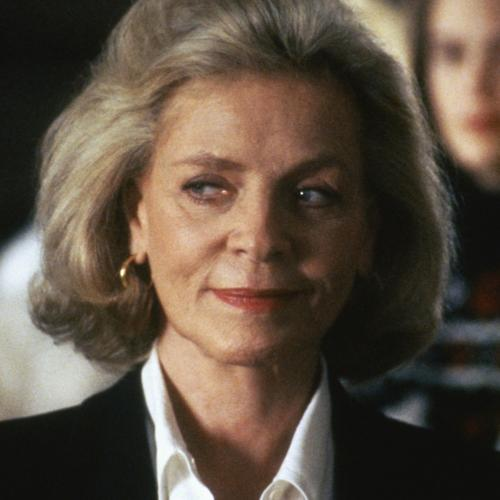

In [4]:
females = list(data_dir.glob('female/*.jpg'))
PIL.Image.open(str(females[0]))

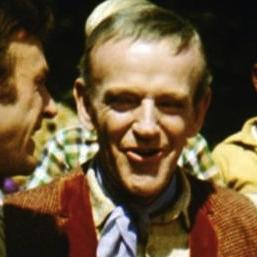

In [5]:
males = list(data_dir.glob('male/*.jpg'))
PIL.Image.open(str(males[0]))

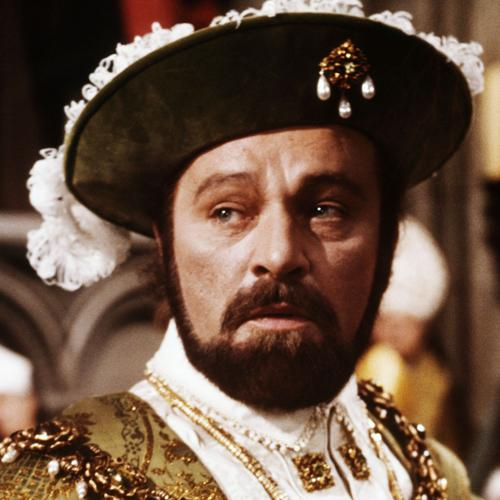

In [6]:
PIL.Image.open(str(males[111]))

In [7]:
batch_size = 32
img_height = 180
img_width = 180

In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split = 0.2,
    subset = 'training',
    seed=11,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

Found 452261 files belonging to 2 classes.
Using 361809 files for training.


I0000 00:00:1769222644.029873   17293 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9558 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:0a:00.0, compute capability: 8.9


In [9]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split = 0.2,
    subset='validation',
    seed=11,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

Found 452261 files belonging to 2 classes.
Using 90452 files for validation.


In [10]:
class_names = train_ds.class_names
class_names

['female', 'male']

2026-01-23 21:44:10.474046: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


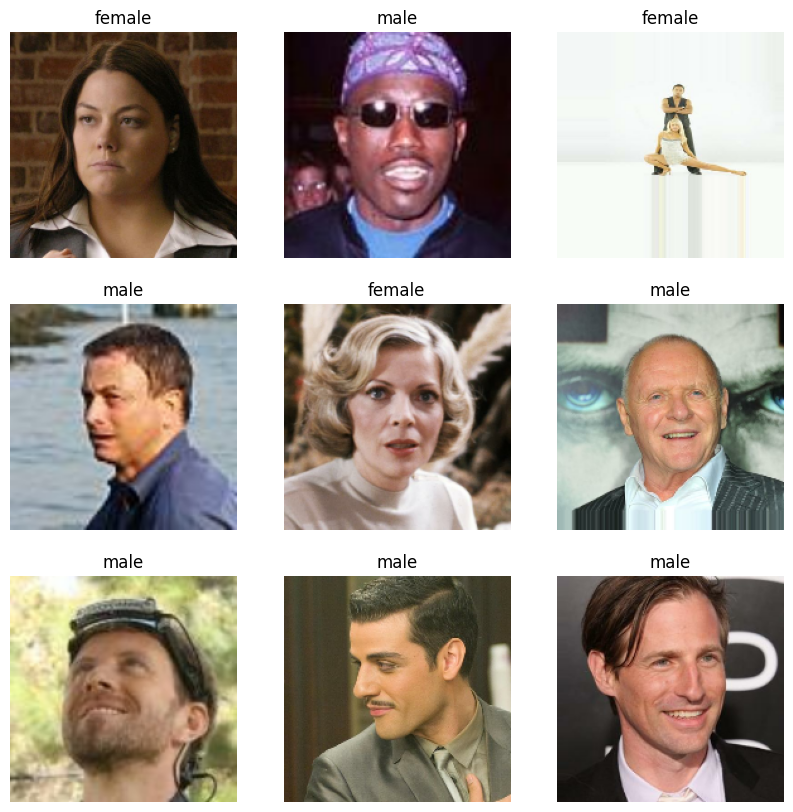

In [11]:
plt.figure(figsize=(10,10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('off')

In [12]:
for image_batch, labels_batch in train_ds:
    print(image_batch.shape)
    print(labels_batch.shape)
    break

(32, 180, 180, 3)
(32,)


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [13]:
from tensorflow.keras import layers
num_classes = len(class_names)

model = tf.keras.models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
    layers.Conv2D(16,3,padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

/mnt/c/Users/Walker/Documents/website_1/notebooks/tf/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [14]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,898 (15.22 MB)

 Trainable params: 3,988,898 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
epochs=10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/10


2026-01-23 21:44:13.035878: I external/local_xla/xla/service/service.cc:163] XLA service 0x716d7c002d10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-23 21:44:13.035931: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4070, Compute Capability 8.9
2026-01-23 21:44:13.135756: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-23 21:44:13.435505: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91800
2026-01-23 21:44:13.506371: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-01-23 21:44:13.836572: I e

   12/11307 ━━━━━━━━━━━━━━━━━━━━ 2:50 15ms/step - accuracy: 0.4704 - loss: 0.8705

I0000 00:00:1769222659.303462   17534 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


11307/11307 ━━━━━━━━━━━━━━━━━━━━ 611s 53ms/step - accuracy: 0.7254 - loss: 0.5597 - val_accuracy: 0.7483 - val_loss: 0.5357
Epoch 2/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 243s 22ms/step - accuracy: 0.7481 - loss: 0.5301 - val_accuracy: 0.7499 - val_loss: 0.5317
Epoch 3/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 244s 22ms/step - accuracy: 0.7548 - loss: 0.5145 - val_accuracy: 0.7471 - val_loss: 0.5339
Epoch 4/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 227s 20ms/step - accuracy: 0.7615 - loss: 0.4982 - val_accuracy: 0.7457 - val_loss: 0.5443
Epoch 5/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 228s 20ms/step - accuracy: 0.7709 - loss: 0.4787 - val_accuracy: 0.7387 - val_loss: 0.5613
Epoch 6/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 228s 20ms/step - accuracy: 0.7796 - loss: 0.4595 - val_accuracy: 0.7360 - val_loss: 0.5825
Epoch 7/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 266s 24ms/step - accuracy: 0.7894 - loss: 0.4403 - val_accuracy: 0.7301 - val_loss: 0.6061
Epoch 8/10
11307/11307 ━━━━━━━━━━━━━━━━━━━━ 229s 20ms/step - accur

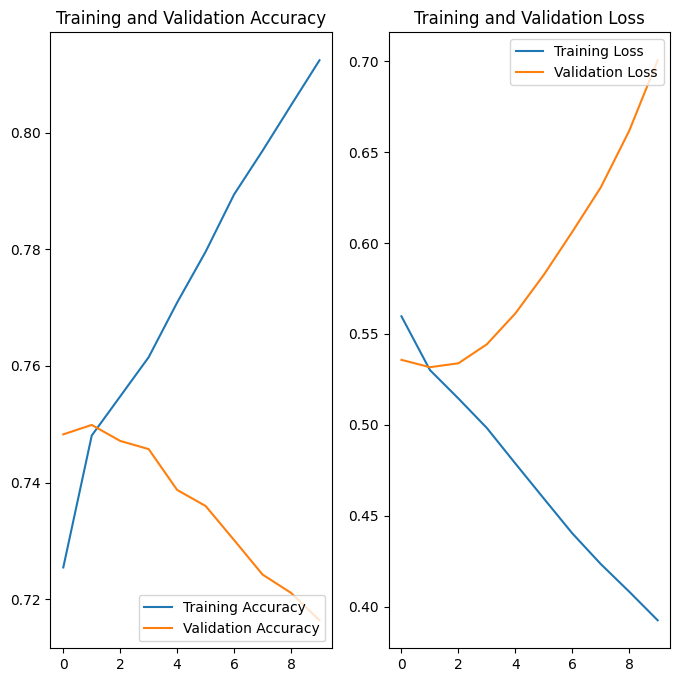

In [18]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()


In [23]:
model.save('/mnt/c/Users/Walker/Documents/website_1/models/gender_model.keras')

In [25]:
for image, label in val_ds.take(1):
    print(model.predict(image))
    break

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 545ms/step
[[-2.0349057   1.8869452 ]
 [-1.3523973   0.616252  ]
 [-0.7561737  -0.08794256]
 [-2.2169693   0.27454048]
 [-0.6696356   0.35034138]
 [ 0.38880855 -6.0773582 ]
 [-0.56189483  0.3083803 ]
 [-2.533577   -2.3260684 ]
 [-0.3745219  -1.7096707 ]
 [-1.1806182   0.40703845]
 [-2.088424    0.90290743]
 [-5.2313757   0.2569576 ]
 [-0.56383175  0.30913466]
 [-1.9644617   0.8546286 ]
 [-1.7192973  -0.07432671]
 [-1.8817457  -2.2570305 ]
 [-1.8876883  -0.2583403 ]
 [-0.3255915   0.21634881]
 [-1.4427223  -0.6227313 ]
 [-2.5063848   1.3097435 ]
 [-0.73994255 -2.4351156 ]
 [-2.587179    1.0971541 ]
 [-1.347555    0.6143661 ]
 [-0.40473634  0.5593582 ]
 [-0.90372914 -6.4040413 ]
 [-2.2194278   2.4329205 ]
 [-1.23428     2.368624  ]
 [-1.9531186  -0.29370117]
 [-1.5132674  -1.5906425 ]
 [-0.6827734   2.665685  ]
 [-0.52182573 -1.8005083 ]
 [-1.946061    0.84746224]]
